# Model A: neural network — working copy

This copy contains Person 1's data preparation followed by Person 2's Model A section.
**Provisional model choice:** a multilayer perceptron (MLP). Confirm that Model B is a different
type of classifier before using this comparison in the submission.

Run all cells in order. The supplied dataset is downloaded by the original loading cells.
The new Model A section starts at **Model A — c: choice and rationale**.

Changes to the inherited preparation: negative placeholder timestamps for participants 8 and 9 are reconstructed from clock order; overnight sleep end dates are rolled forward when
necessary; labels are rebuilt; stale outputs are cleared. The original participant split
and RR cleaning rule are retained. Agree these corrections and the seven input features
with both teammates so both models use identical labels, features and splits.

Labels are a **sleep-period proxy**: everything from onset to out-of-bed is labelled asleep.
Within-period awakenings cannot be located from the episode summary and remain label noise.
Participant 11 lacks a sleep record and is excluded, rather than assumed awake.

AI assistance was used to review the handoff, identify the midnight issue, and prepare this
implementation and explanatory notes. Review and understand each step, check it against the
assignment's AI-use rules, and describe your actual use accurately in the report.

Later AI additions (Claude, review session): zoomed accuracy axis on the learning curves; simple reference rules derived from training data; grouped permutation importance on validation; per-person test timelines. The AI-written results draft was removed — the discussion is to be written by Person 2.


# CS51009 Machine Learning Assignment
## Sleep Detection from Wearable Data (MMASH)

MMASH (Multilevel Monitoring of Activity and Sleep in Healthy people) is a public dataset hosted on PhysioNet. It follows 22 healthy young adults for about 24 hours of normal daily life. Each person wore an ECG device that recorded the time between every heartbeat (the RR, or inter-beat, interval) and a wrist-worn activity monitor (an actigraph) that recorded movement, steps, body position and heart rate. They also kept an activity diary, completed questionnaires, gave saliva samples from which cortisol and melatonin levels were measured, and had their sleep recorded.

The sources produce different kinds of data. The activity monitor and heartbeat summaries give one row per second. The sleep records give one row per sleep episode. The saliva and questionnaire data give a few values per person. Bringing these together is part of the problem.

The task is described at the end of this notebook.

## The data

Three files are provided.

| File | One row per | Contents |
|---|---|---|
| `timeseries.csv` | person and second | `user_id`, `timestamp`, the activity monitor columns (movement on three axes, vector magnitude, steps, heart rate and body position) and heartbeat summaries for that second (`rr_mean`, `rr_min`, `rr_max` in seconds, and `n_beats`)|
| `sleep.csv` | sleep episode | `user_id`, `episode`, and the start and end times and summary statistics of each recorded sleep episode |
| `subjects.csv` | person | Background information, questionnaire scores (columns starting `q_`) and saliva hormone levels (columns starting `cortisol_` and `melatonin_`) |

**Things to know before you start**

- **There is no ready-made sleep label.** `sleep.csv` records when each person slept. Turning that into a label for the time series is part of the problem. Its times are in a different format from `timestamp` and may need converting.
- **Dates are placeholders.** The real dates were removed and `timestamp` starts at 2000-01-01. Only the time of day and the order of rows matter. Recordings cross midnight. The `day` and `time` columns hold the same information as `timestamp`.
- **The heartbeat data is raw.** Each second holds a summary of the beat intervals detected in that second. Seconds with no detected beat are missing. Beats can be missed or falsely detected, and some people have gaps in the recording. Nothing has been cleaned.
- **Saliva and questionnaire values are single numbers per person**, not time series.
- **Only 22 people.** Keep this in mind when you decide how much to trust any result.

In [ ]:
# Downloads the dataset files.
import gdown

files = {
    'timeseries.csv': '1IuQib_tPj83kV8XTbCoL6goOZuyOgRB3',
    'sleep.csv': '17ild_0EAWa83siQBbKlZX1uOeeon2Ikx',
    'subjects.csv': '1Uet3e6BQRvinszc8FEaZJC0YH1dcKYry',
}
for name, file_id in files.items():
    gdown.download(id=file_id, output=name, quiet=True)

In [1]:
# Checks that all three files downloaded properly.
import os

for f in ['timeseries.csv', 'sleep.csv', 'subjects.csv']:
    assert os.path.exists(f) and os.path.getsize(f) > 1_000, f'{f} did not download properly. Rerun the download cell.'
print('All files downloaded.')

All files downloaded.


In [2]:
# Imports the datasets and displays the first 5 rows of the time series.
import numpy as np
import pandas as pd

timeseries = pd.read_csv('timeseries.csv', parse_dates=['timestamp'])
sleep = pd.read_csv('sleep.csv')
subjects = pd.read_csv('subjects.csv')

timeseries.head()

In [3]:
# Displays the sleep episodes.
sleep

In [4]:
# Displays the per-person data (background, questionnaires and saliva).
subjects

In [5]:
# Recording length, share of seconds with a detected heartbeat, and number of sleep episodes for each person.
summary = pd.DataFrame({
    'hours_recorded': timeseries.groupby('user_id').size() / 3600,
    'fraction_seconds_with_beat': timeseries['rr_mean'].notna().groupby(timeseries['user_id']).mean(),
    'sleep_episodes': sleep.groupby('user_id').size(),
})
summary

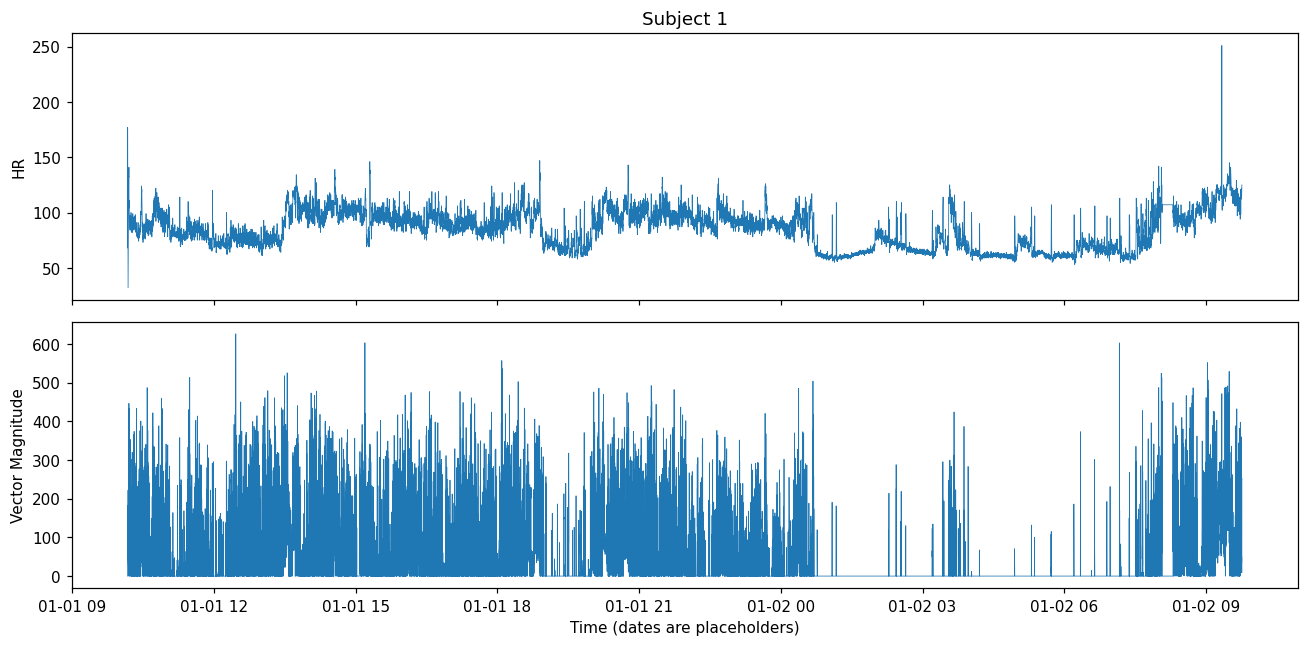

In [6]:
# One person: heart rate and movement over the recording.
import matplotlib.pyplot as plt

example_id = timeseries['user_id'].iloc[0]
sub = timeseries[timeseries['user_id'] == example_id]

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(sub['timestamp'], sub['HR'], linewidth=0.5)
axes[0].set_ylabel('HR')
axes[0].set_title(f'Subject {example_id}')
axes[1].plot(sub['timestamp'], sub['Vector Magnitude'], linewidth=0.5)
axes[1].set_ylabel('Vector Magnitude')
axes[1].set_xlabel('Time (dates are placeholders)')
plt.tight_layout()
plt.show()

count    1.314618e+06
mean     8.411020e-01
std      2.022192e-01
min      5.500000e-02
25%      7.070000e-01
50%      8.240000e-01
75%      9.620000e-01
max      7.613000e+00
Name: rr_mean, dtype: float64


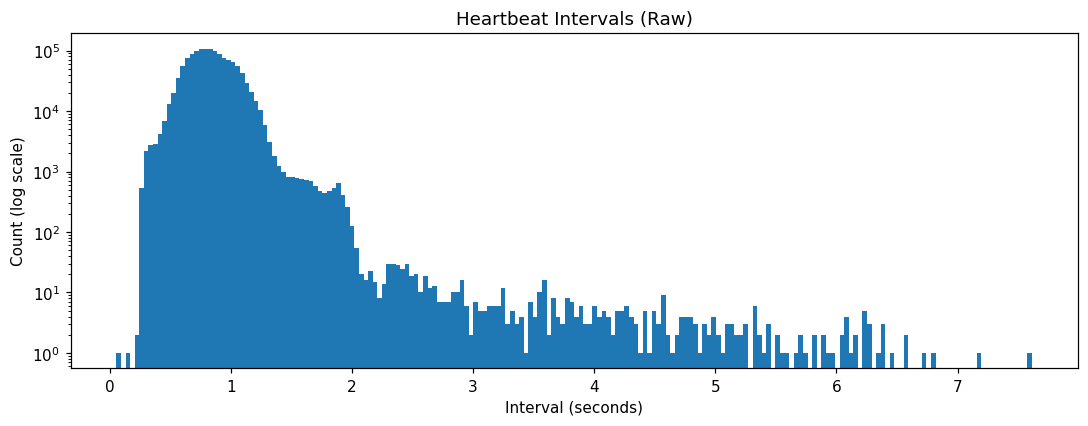

In [7]:
# Heartbeat intervals (per-second mean) for all subjects. Look carefully at the range of values.
print(timeseries['rr_mean'].describe())

plt.figure(figsize=(10, 4))
plt.hist(timeseries['rr_mean'].dropna(), bins=200)
plt.yscale('log')
plt.title('Heartbeat Intervals (Raw)')
plt.xlabel('Interval (seconds)')
plt.ylabel('Count (log scale)')
plt.tight_layout()
plt.show()

## The task

Predict, at whatever time resolution you choose, whether each person is **asleep** or **awake**.

How you do this is up to you. The ground truth comes from `sleep.csv`, and turning the recorded sleep episodes into labels for the time series is part of the problem. You can use any of the other data provided: the activity monitor signals, the heartbeat summaries, the diary, and the per-person background, questionnaire and saliva data. Part of the problem is deciding which of these help and which get in the way, and how to clean, align and combine them. Use any methods, models and libraries you like, and explore as much as you want.

Using `sleep.csv` as an input when predicting would just reproduce the answer, so it should only be used to build and check your labels. Whatever approach you take, a method is only useful if it works for people it was not trained on, so think about how you will show that.

# Data preparation
Define asleep = 1 for timestamps from recorded sleep onset up to (but excluding) out-of-bed;
awake = 0 outside those intervals for participants with sleep records. Unknown labels remain
missing for participants with no sleep record. This interval definition ignores awakenings.
Reconstruct negative placeholder days from acquisition-order clock rollovers. Correct an end datetime earlier than its onset by advancing it to the next day.

In [8]:
# Repair negative placeholder days using the within-person recorded clock order.
# The supplied rows are in acquisition order; do not sort by corrupted timestamps.
for uid, frame in timeseries.groupby('user_id', sort=False):
    if (frame['day'] < 1).any():
        clock = pd.to_timedelta(frame['time'])
        rollovers = (clock.diff() < pd.Timedelta(0)).cumsum()
        assert int(rollovers.max()) == 1, 'Unexpected clock order: inspect manually.'
        assert frame.iloc[0]['day'] == 1, 'Unexpected recording start day.'
        repaired = pd.Timestamp('2000-01-01') + pd.to_timedelta(rollovers, unit='D') + clock
        timeseries.loc[frame.index, 'timestamp'] = repaired
        timeseries.loc[frame.index, 'day'] = 1 + rollovers
        print('Repaired negative placeholder dates for participant:', uid)

sleep['sleep_start'] = (pd.Timestamp('2000-01-01')
    + pd.to_timedelta(sleep['Onset Date'] - 1, unit='D')
    + pd.to_timedelta(sleep['Onset Time'] + ':00'))
sleep['sleep_end'] = (pd.Timestamp('2000-01-01')
    + pd.to_timedelta(sleep['Out Bed Date'] - 1, unit='D')
    + pd.to_timedelta(sleep['Out Bed Time'] + ':00'))
overnight = sleep['sleep_end'] < sleep['sleep_start']
sleep.loc[overnight, 'sleep_end'] += pd.Timedelta(days=1)
assert (sleep['sleep_end'] > sleep['sleep_start']).all(), 'Check invalid sleep intervals.'
print('Overnight date corrections:', sleep.loc[overnight, 'user_id'].tolist())

timeseries['label'] = np.nan
known_people = sleep['user_id'].unique()
timeseries.loc[timeseries['user_id'].isin(known_people), 'label'] = 0
for _, episode in sleep.iterrows():
    mask = ((timeseries['user_id'] == episode['user_id'])
        & (timeseries['timestamp'] >= episode['sleep_start'])
        & (timeseries['timestamp'] < episode['sleep_end']))
    timeseries.loc[mask, 'label'] = 1
print(timeseries['label'].value_counts(dropna=False))
label_counts = pd.crosstab(timeseries['user_id'], timeseries['label'])
print(label_counts)
assert (label_counts.reindex(known_people, fill_value=0).get(1.0, 0) > 0).all(), \
    'A recorded sleeper has no sleep rows: check date alignment.'

Repaired negative placeholder dates for participant: 8
Repaired negative placeholder dates for participant: 9
Overnight date corrections: [3, 5, 13, 19]
label
0.0    1038669
1.0     355647
NaN      68362
Name: count, dtype: int64
label      0.0    1.0
user_id              
1        49769  18167
2        50620  10242
3        49163  18609
4        51439  13357
5        45290  19764
6        48675  18725
7        48320  20394
8        45719  15959
9        40716  23405
10       50714   7902
12       51132  17607
13       51809  15541
14       49239  18756
15       58893  12152
16       48195  21655
17       51091  17260
18       51251  14660
19       46306  22020
20       46618  18122
21       52954  14232
22       50756  17118


In [9]:
asleep = timeseries[timeseries['label'] == 1]
awake = timeseries[timeseries['label'] == 0]

## Heartbeat histograms before cleaning

count    1.314618e+06
mean     8.411020e-01
std      2.022192e-01
min      5.500000e-02
25%      7.070000e-01
50%      8.240000e-01
75%      9.620000e-01
max      7.613000e+00
Name: rr_mean, dtype: float64


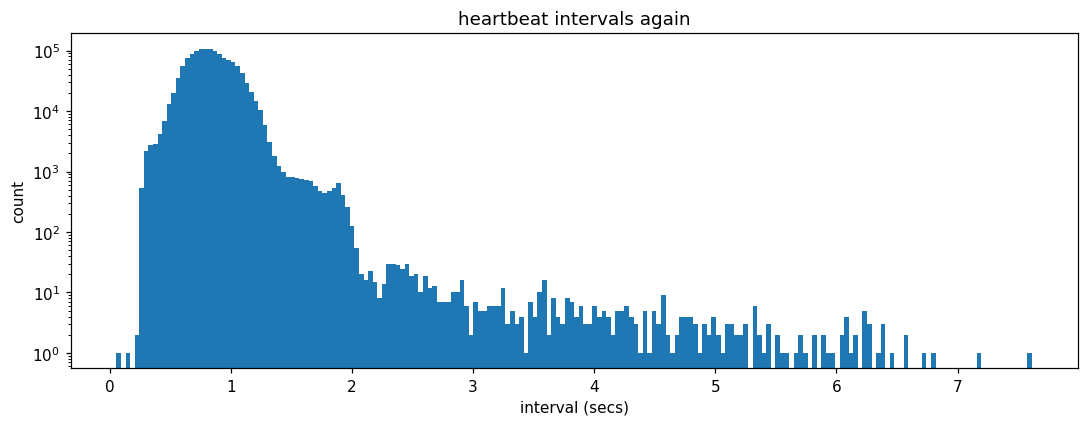

In [10]:
# hb intervals graphs
# no clean
import matplotlib.pyplot as plt

print(timeseries['rr_mean'].describe())

plt.figure(figsize=(10, 4))
plt.hist(timeseries['rr_mean'], bins=200)
plt.yscale('log')
plt.title('heartbeat intervals again')
plt.xlabel('interval (secs)')
plt.ylabel('count')
plt.tight_layout()
plt.show()

Clean heartbeat data
- drop any duplicates
- address outliers
- handle missing values

In [11]:
# check duplicates
print(timeseries.duplicated().sum())

# check missings
print(timeseries.isna().sum())

# check outliers
print(timeseries[['rr_mean', 'rr_min', 'rr_max', 'n_beats']].describe())

for col in ['rr_mean', 'rr_min', 'rr_max']:
  print(col, ((timeseries[col] < 0.3) | (timeseries[col] > 2)).sum())

0
Unnamed: 0                    0
user_id                       0
timestamp                     0
Axis1                         0
Axis2                         0
Axis3                         0
Steps                         0
HR                            0
Inclinometer Off              0
Inclinometer Standing         0
Inclinometer Sitting          0
Inclinometer Lying            0
Vector Magnitude              0
day                           0
time                          0
rr_mean                  148060
rr_min                   148060
rr_max                   148060
n_beats                  148060
label                     68362
dtype: int64
            rr_mean        rr_min        rr_max       n_beats
count  1.314618e+06  1.314618e+06  1.314618e+06  1.314618e+06
mean   8.411020e-01  8.365489e-01  8.457753e-01  1.278063e+00
std    2.022192e-01  2.046271e-01  2.048290e-01  4.702661e-01
min    5.500000e-02  5.500000e-02  5.500000e-02  1.000000e+00
25%    7.070000e-01  7.010000e-01  

No full-row duplicates were detected in the supplied run. Outlying RR summaries are marked missing; Model A later imputes missing values using training-set medians. The 0.3–2 second rule is inherited and needs justification in the group report. Also check duplicate (user_id, timestamp) keys.

In [12]:
# replace outliers for now
for col in ['rr_mean', 'rr_min', 'rr_max']:
  timeseries.loc[
      (timeseries[col] < 0.3) | (timeseries[col] > 2),
      col
  ] = np.nan

Redo the histographs now clean

count    1.312331e+06
mean     8.402948e-01
std      1.913057e-01
min      3.000000e-01
25%      7.070000e-01
50%      8.240000e-01
75%      9.620000e-01
max      2.000000e+00
Name: rr_mean, dtype: float64


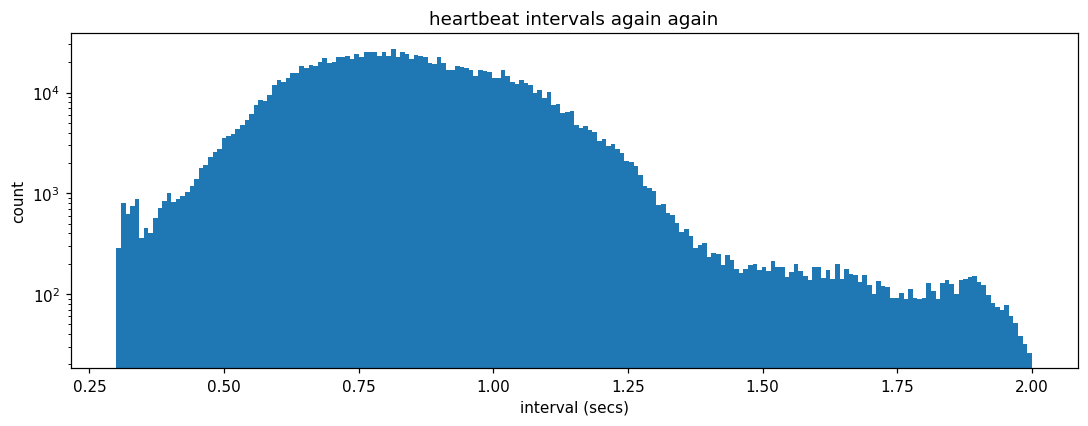

In [13]:
# hb intervals graphs
# nice clean
import matplotlib.pyplot as plt

print(timeseries['rr_mean'].describe())

plt.figure(figsize=(10, 4))
plt.hist(timeseries['rr_mean'], bins=200)
plt.yscale('log')
plt.title('heartbeat intervals again again')
plt.xlabel('interval (secs)')
plt.ylabel('count')
plt.tight_layout()
plt.show()

## Feature histograms
Compare the class distributions. Counts reflect the different class sizes; normalised histograms with shared bins are more suitable for comparing distribution shapes.

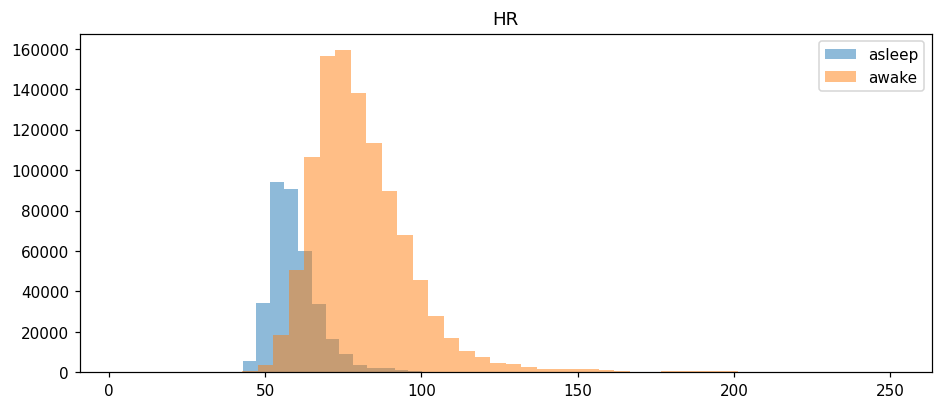

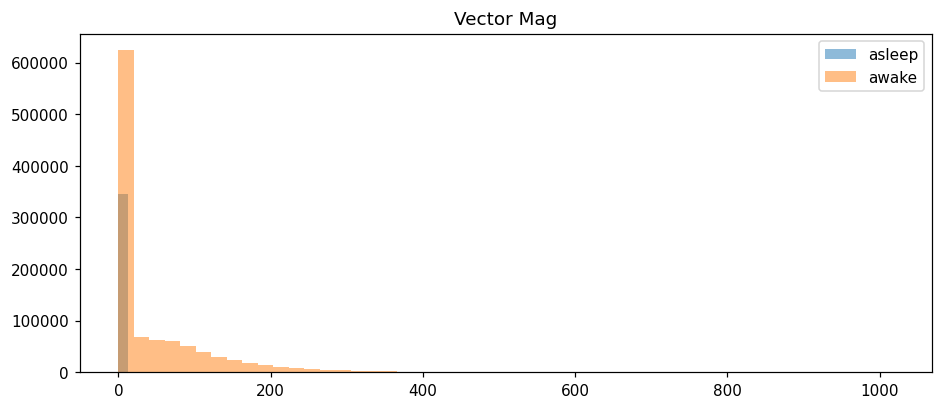

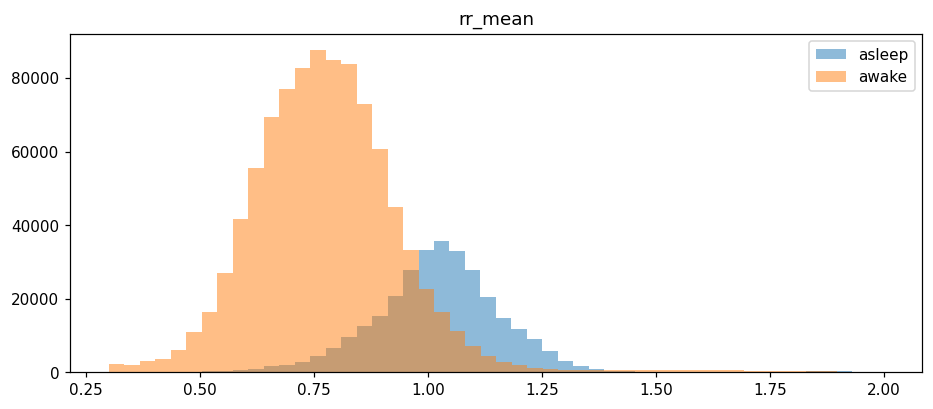

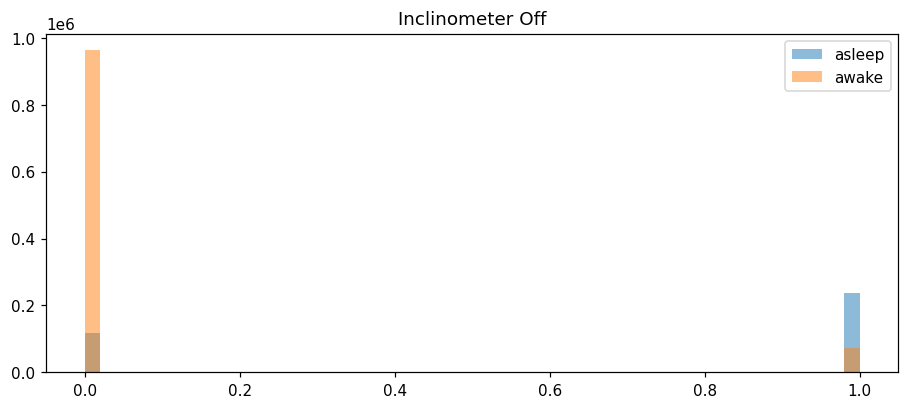

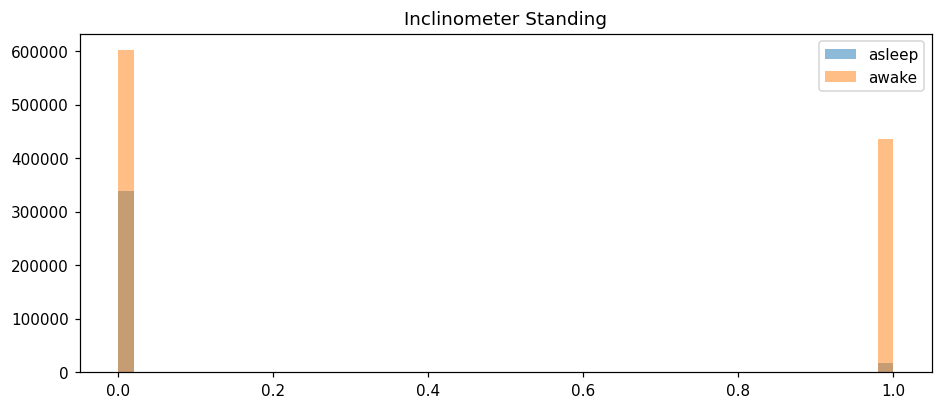

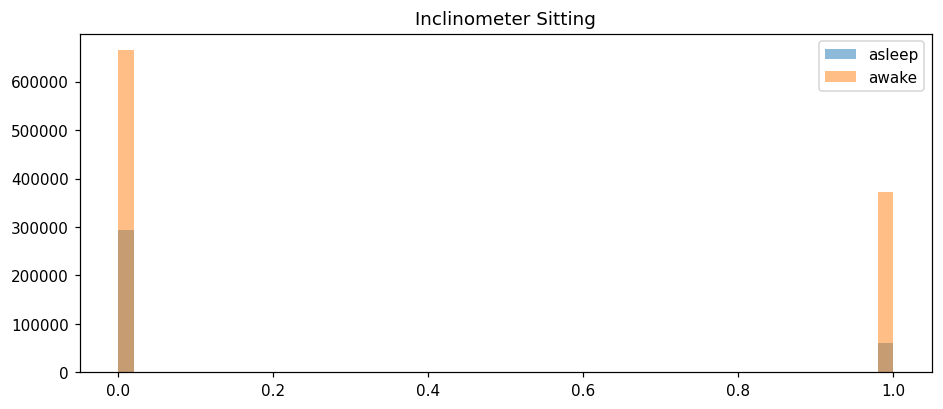

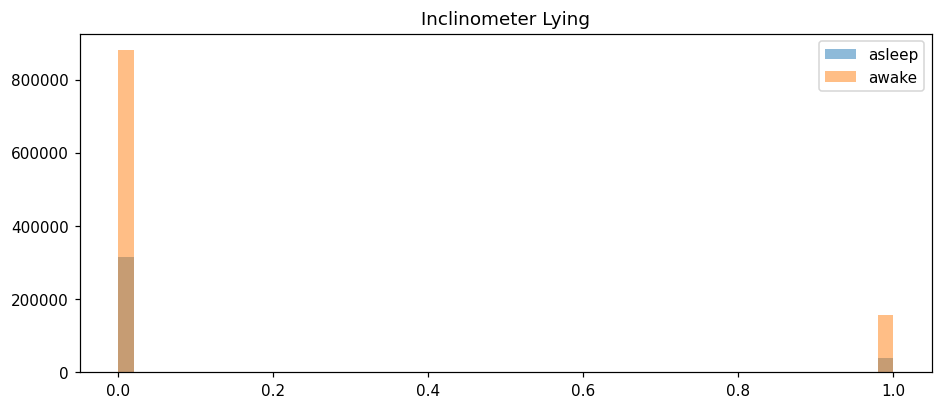

In [14]:
# wait im stupid i put this in the wrong place
# plot plot plot
# to the tune of shots shots shots though

import matplotlib.pyplot as plt

# HR
plt.figure(figsize=(10, 4))
plt.hist(timeseries[timeseries['label'] == 1]['HR'].dropna(), bins=50, alpha=0.5, label='asleep')
plt.hist(timeseries[timeseries['label'] == 0]['HR'].dropna(), bins=50, alpha=0.5, label='awake')
plt.title('HR')
plt.legend()
plt.show()

# vector mag
plt.figure(figsize=(10, 4))
plt.hist(timeseries[timeseries['label'] == 1]['Vector Magnitude'].dropna(), bins=50, alpha=0.5, label='asleep')
plt.hist(timeseries[timeseries['label'] == 0]['Vector Magnitude'].dropna(), bins=50, alpha=0.5, label='awake')
plt.title('Vector Mag')
plt.legend()
plt.show()

# rrmean
plt.figure(figsize=(10, 4))
plt.hist(timeseries[timeseries['label'] == 1]['rr_mean'].dropna(), bins=50, alpha=0.5, label='asleep')
plt.hist(timeseries[timeseries['label'] == 0]['rr_mean'].dropna(), bins=50, alpha=0.5, label='awake')
plt.title('rr_mean')
plt.legend()
plt.show()

# i know this is inefficent im in too deep
# and im too lazy to fix it right now
# can smooth it out later

# inc off
plt.figure(figsize=(10, 4))
plt.hist(timeseries[timeseries['label'] == 1]['Inclinometer Off'].dropna(), bins=50, alpha=0.5, label='asleep')
plt.hist(timeseries[timeseries['label'] == 0]['Inclinometer Off'].dropna(), bins=50, alpha=0.5, label='awake')
plt.title('Inclinometer Off')
plt.legend()
plt.show()

# inc stand
plt.figure(figsize=(10, 4))
plt.hist(timeseries[timeseries['label'] == 1]['Inclinometer Standing'].dropna(), bins=50, alpha=0.5, label='asleep')
plt.hist(timeseries[timeseries['label'] == 0]['Inclinometer Standing'].dropna(), bins=50, alpha=0.5, label='awake')
plt.title('Inclinometer Standing')
plt.legend()
plt.show()

# inc sit
plt.figure(figsize=(10, 4))
plt.hist(timeseries[timeseries['label'] == 1]['Inclinometer Sitting'].dropna(), bins=50, alpha=0.5, label='asleep')
plt.hist(timeseries[timeseries['label'] == 0]['Inclinometer Sitting'].dropna(), bins=50, alpha=0.5, label='awake')
plt.title('Inclinometer Sitting')
plt.legend()
plt.show()

# inc lie
plt.figure(figsize=(10, 4))
plt.hist(timeseries[timeseries['label'] == 1]['Inclinometer Lying'].dropna(), bins=50, alpha=0.5, label='asleep')
plt.hist(timeseries[timeseries['label'] == 0]['Inclinometer Lying'].dropna(), bins=50, alpha=0.5, label='awake')
plt.title('Inclinometer Lying')
plt.legend()
plt.show()


## Interpretation to complete
Write interpretations from the corrected plots. Overlap suggests a feature alone cannot perfectly separate classes. These plots do not establish causal or model-specific feature importance.

# Splitting the Data

The labelled participants are divided into 13 training, 4 validation and 4 test participants (approximately 62%, 19%, 19%). Counts of seconds will differ. Keeping each person in one set targets generalisation to unseen participants. The random seed is 4.

In [15]:
# splittin time

# obvs take the labelled data only
data = timeseries.dropna(subset=['label']).copy()

from sklearn.model_selection import train_test_split

# use the ids
people = data['user_id'].unique()

# save 20% to test
train_val_people, test_people = train_test_split(people, test_size= 4, random_state=4)

# split remaining into 20% val and 60% train
train_people, val_people = train_test_split( train_val_people, test_size= 4, random_state=4)

# create datasets
train = data[data['user_id'].isin(train_people)]
validation = data[data['user_id'].isin(val_people)]
test = data[data['user_id'].isin(test_people)]

# double check uniqueness
print(train['user_id'].nunique())
print(validation['user_id'].nunique())
print(test['user_id'].nunique())


13
4
4


# Model A — c: choice and rationale

**Candidate choice, to explain in your own words:** an MLP is a feedforward neural network
that can learn nonlinear combinations of heart rate, movement and posture. A small network
limits complexity given only 21 labelled participants. It is a different model family from a
tree-based classifier, if that is what Model B uses. It is not assumed to be the best model.
Limitations include sensitivity to scaling and tuning, limited interpretability and the
absence of temporal context: this model classifies each second independently.

Seven predefined features are used: HR, Vector Magnitude, rr_mean and the four Inclinometer
columns. Identity, index and date/time are excluded. Confirm this feature set with Model B.
Median imputation and standardisation are fitted only on training rows. The validation set
selects the network/checkpoint; the test set is used only after that selection.

Reference: [scikit-learn MLPClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html).
One `partial_fit` call makes one training pass, allowing explicit curves on the supplied
participant-disjoint validation set rather than an internal random row split.

In [16]:
from pathlib import Path
from copy import deepcopy
import json
import time
import sklearn
import joblib
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, log_loss,
    confusion_matrix, ConfusionMatrixDisplay, classification_report, f1_score)
from threadpoolctl import threadpool_limits

OUTPUT_DIR = Path('model_a_results')
OUTPUT_DIR.mkdir(exist_ok=True)
SEED = 42
FEATURE_COLUMNS = ['HR', 'Vector Magnitude', 'rr_mean', 'Inclinometer Off',
    'Inclinometer Standing', 'Inclinometer Sitting', 'Inclinometer Lying']
MAX_EPOCHS = 25
PATIENCE = 4
MIN_DELTA = 1e-4
CANDIDATES = [
    {'name': 'MLP_16', 'hidden_layer_sizes': (16,), 'alpha': 0.001,
     'learning_rate_init': 0.001},
    {'name': 'MLP_32_16', 'hidden_layer_sizes': (32, 16), 'alpha': 0.001,
     'learning_rate_init': 0.001},
]
print('scikit-learn:', sklearn.__version__)

scikit-learn: 1.8.0


## Check the handoff and prepare inputs
The following assertions stop training if participants overlap or labels are absent.
Duplicates are checked by participant and timestamp rather than by the exported row index.
No test feature values or test labels are used to fit preprocessing or select models.

In [17]:
splits = {'training': train, 'validation': validation, 'test': test}
people_sets = [set(frame['user_id']) for frame in splits.values()]
assert all(not people_sets[i] & people_sets[j]
    for i in range(3) for j in range(i+1, 3)), 'Participant leakage.'
split_rows = []
for name, frame in splits.items():
    assert len(frame) > 0
    assert frame['label'].notna().all()
    assert set(frame['label'].unique()) == {0, 1}, f'{name} lacks a class.'
    assert not frame.duplicated(['user_id', 'timestamp']).any(), 'Duplicate time keys.'
    assert all(col in frame for col in FEATURE_COLUMNS)
    split_rows.append({'split': name, 'participants': frame['user_id'].nunique(),
        'rows': len(frame), 'asleep_fraction': frame['label'].mean(),
        'participant_ids': sorted(frame['user_id'].unique().tolist())})
split_summary = pd.DataFrame(split_rows)
display(split_summary)
split_summary.to_csv(OUTPUT_DIR / 'split_summary.csv', index=False)

X_train = train[FEATURE_COLUMNS].replace([np.inf, -np.inf], np.nan).copy()
X_val = validation[FEATURE_COLUMNS].replace([np.inf, -np.inf], np.nan).copy()
y_train = train['label'].astype(int).to_numpy()
y_val = validation['label'].astype(int).to_numpy()
assert X_train.notna().any().all(), 'A training feature is entirely missing.'
imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(imputer.fit_transform(X_train)).astype(np.float32)
X_val_scaled = scaler.transform(imputer.transform(X_val)).astype(np.float32)
assert np.isfinite(X_train_scaled).all() and np.isfinite(X_val_scaled).all()
print('Features:', FEATURE_COLUMNS)
print('Training imputation medians:', dict(zip(FEATURE_COLUMNS, imputer.statistics_)))

Features: ['HR', 'Vector Magnitude', 'rr_mean', 'Inclinometer Off', 'Inclinometer Standing', 'Inclinometer Sitting', 'Inclinometer Lying']
Training imputation medians: {'HR': np.float64(74.0), 'Vector Magnitude': np.float64(0.0), 'rr_mean': np.float64(0.813), 'Inclinometer Off': np.float64(0.0), 'Inclinometer Standing': np.float64(0.0), 'Inclinometer Sitting': np.float64(0.0), 'Inclinometer Lying': np.float64(0.0)}


,split,participants,rows,asleep_fraction,participant_ids
0,training,13,871338,0.266069,"[2, 3, 6, 7, 8, 9, 13, 14, 15, 16, 17, 19, 22]"
1,validation,4,258320,0.232011,"[5, 10, 12, 18]"
2,test,4,264658,0.241361,"[1, 4, 20, 21]"


# Model A — e: training and validation
Two network sizes are compared while holding other settings fixed. Adam, ReLU, batch size
1024 and L2 regularisation are used. This is a small architecture search, not an exhaustive
hyperparameter optimisation. Each epoch is a full pass over all training seconds.

Both curves are computed after the epoch on the full respective sets. The plotted loss is
binary cross-entropy (without the L2 penalty), so training and validation losses are comparable.
Stopping occurs after four epochs without a validation-loss improvement of at least 0.0001,
or after 25 epochs. The lowest validation-loss checkpoint is retained, including smaller
improvements; the candidate with the lowest such loss is selected. No class rebalancing is
applied in this required-task version. Balanced accuracy and a majority baseline help expose
misleading overall accuracy without changing the training distribution.

In [18]:
def fit_candidate(config, x_train, target_train, x_val, target_val,
                  max_epochs=MAX_EPOCHS, patience=PATIENCE, verbose=True):
    settings = {key: value for key, value in config.items() if key != 'name'}
    model = MLPClassifier(**settings, activation='relu', solver='adam',
        batch_size=min(1024, len(target_train)), shuffle=True, random_state=SEED,
        early_stopping=False, max_iter=1)
    best_loss = np.inf
    progress_loss = np.inf
    stale = 0
    history = []
    best_model = None
    best_epoch = None
    with threadpool_limits(limits=1):
        for epoch in range(1, max_epochs + 1):
            started = time.perf_counter()
            model.partial_fit(x_train, target_train, classes=np.array([0, 1]))
            p_train = model.predict_proba(x_train)
            p_val = model.predict_proba(x_val)
            row = {'epoch': epoch,
                'train_loss': log_loss(target_train, p_train, labels=[0, 1]),
                'val_loss': log_loss(target_val, p_val, labels=[0, 1]),
                'train_accuracy': accuracy_score(target_train, p_train.argmax(axis=1)),
                'val_accuracy': accuracy_score(target_val, p_val.argmax(axis=1)),
                'seconds': time.perf_counter() - started}
            history.append(row)
            if row['val_loss'] < best_loss:
                best_loss = row['val_loss']
                best_model = deepcopy(model)
                best_epoch = epoch
            if row['val_loss'] < progress_loss - MIN_DELTA:
                progress_loss = row['val_loss']
                stale = 0
            else:
                stale += 1
            if verbose:
                print(f"{config['name']} epoch {epoch:02d}: "
                      f"train loss={row['train_loss']:.4f}, val loss={row['val_loss']:.4f}, "
                      f"val accuracy={row['val_accuracy']:.4f}", flush=True)
            if stale >= patience:
                break
    return {'config': config, 'model': best_model, 'best_epoch': best_epoch,
            'val_loss': best_loss, 'history': pd.DataFrame(history)}

runs = [fit_candidate(config, X_train_scaled, y_train, X_val_scaled, y_val)
        for config in CANDIDATES]
selected_run = min(runs, key=lambda run: run['val_loss'])
model_a = selected_run['model']
tuning_summary = pd.DataFrame([{'candidate': run['config']['name'],
    'layers': str(run['config']['hidden_layer_sizes']), 'best_epoch': run['best_epoch'],
    'epochs_run': len(run['history']), 'validation_log_loss': run['val_loss'],
    'validation_accuracy': run['history'].loc[
        run['history']['epoch'] == run['best_epoch'], 'val_accuracy'].iloc[0]}
    for run in runs])
display(tuning_summary)
print('Selected:', selected_run['config']['name'], 'epoch', selected_run['best_epoch'])
tuning_summary.to_csv(OUTPUT_DIR / 'tuning_summary.csv', index=False)

MLP_16 epoch 01: train loss=0.2582, val loss=0.3270, val accuracy=0.8733
MLP_16 epoch 02: train loss=0.2504, val loss=0.3206, val accuracy=0.8786
MLP_16 epoch 03: train loss=0.2468, val loss=0.3162, val accuracy=0.8800
MLP_16 epoch 04: train loss=0.2448, val loss=0.3138, val accuracy=0.8794
MLP_16 epoch 05: train loss=0.2436, val loss=0.3119, val accuracy=0.8795
MLP_16 epoch 06: train loss=0.2426, val loss=0.3106, val accuracy=0.8793
MLP_16 epoch 07: train loss=0.2419, val loss=0.3106, val accuracy=0.8784
MLP_16 epoch 08: train loss=0.2415, val loss=0.3105, val accuracy=0.8783
MLP_16 epoch 09: train loss=0.2411, val loss=0.3105, val accuracy=0.8780
MLP_16 epoch 10: train loss=0.2409, val loss=0.3105, val accuracy=0.8780
MLP_16 epoch 11: train loss=0.2407, val loss=0.3106, val accuracy=0.8779
MLP_16 epoch 12: train loss=0.2405, val loss=0.3107, val accuracy=0.8779
MLP_16 epoch 13: train loss=0.2403, val loss=0.3107, val accuracy=0.8779
MLP_32_16 epoch 01: train loss=0.2433, val loss=0.3

,candidate,layers,best_epoch,epochs_run,validation_log_loss,validation_accuracy
0,MLP_16,"(16,)",9,13,0.310489,0.878031
1,MLP_32_16,"(32, 16)",21,21,0.306178,0.880218


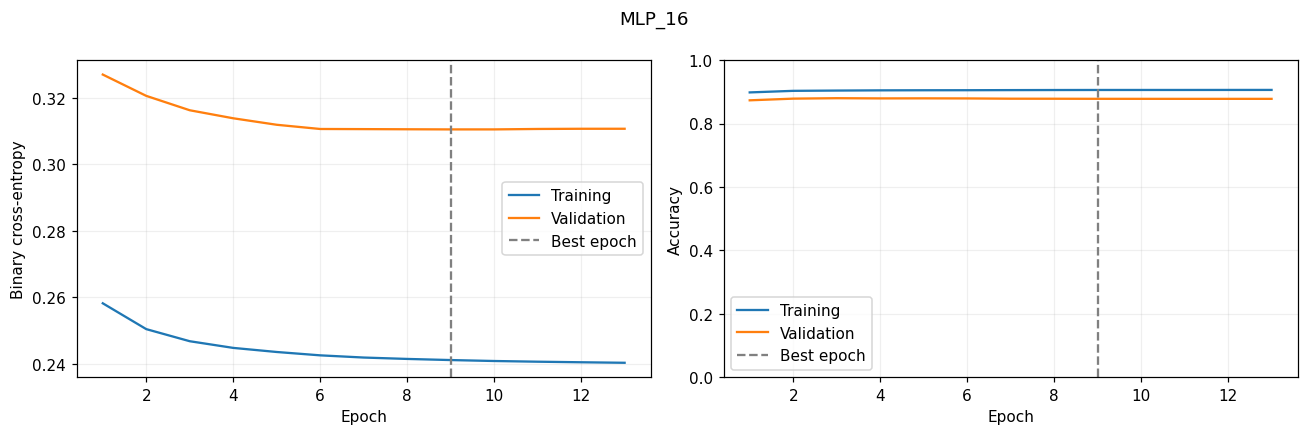

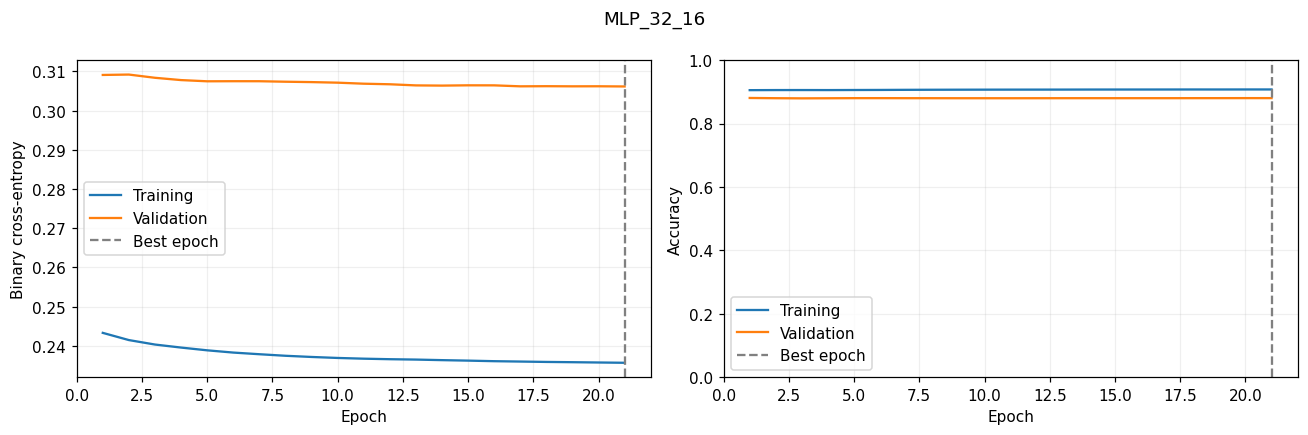

In [19]:
for run in runs:
    history = run['history']
    name = run['config']['name']
    history.to_csv(OUTPUT_DIR / f'{name}_training_history.csv', index=False)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for column, label in [('train_loss', 'Training'), ('val_loss', 'Validation')]:
        axes[0].plot(history['epoch'], history[column], label=label)
    for column, label in [('train_accuracy', 'Training'), ('val_accuracy', 'Validation')]:
        axes[1].plot(history['epoch'], history[column], label=label)
    axes[0].set_ylabel('Binary cross-entropy')
    axes[1].set_ylabel('Accuracy')
    acc_values = history[['train_accuracy', 'val_accuracy']].to_numpy()
    axes[1].set_ylim(acc_values.min() - 0.01, acc_values.max() + 0.01)  # zoomed: a 0–1 axis hides the curves
    for axis in axes:
        axis.axvline(run['best_epoch'], color='grey', linestyle='--', label='Best epoch')
        axis.set_xlabel('Epoch')
        axis.legend()
        axis.grid(alpha=0.2)
    fig.suptitle(name)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f'{name}_learning_curves.png', dpi=180)
    plt.show()

## Reference rules (validation)
A model is only useful if it beats simple alternatives. Two rules are derived from the **training**
participants only: the share of each class with `Inclinometer Off` = 1, and with zero movement. They are
fixed before looking at validation or test results and are reported alongside Model A, not tuned.


In [ ]:
def rule_predictions(frame):
    return {
        'Inclinometer Off': (frame['Inclinometer Off'] == 1).astype(int).to_numpy(),
        'Off and no movement': ((frame['Inclinometer Off'] == 1)
                                & (frame['Vector Magnitude'] == 0)).astype(int).to_numpy(),
    }

def summarise(name, y_true, y_pred):
    cm_ = confusion_matrix(y_true, y_pred, labels=[0, 1])
    r = cm_.diagonal() / cm_.sum(axis=1)
    return {'method': name, 'accuracy': accuracy_score(y_true, y_pred),
            'awake_recall': r[0], 'asleep_recall': r[1],
            'balanced_accuracy': balanced_accuracy_score(y_true, y_pred)}

print('Training-set class profile (share of seconds):')
display(train.groupby('label').agg(
    inclinometer_off=('Inclinometer Off', 'mean'),
    lying=('Inclinometer Lying', 'mean'),
    no_movement=('Vector Magnitude', lambda s: (s == 0).mean())).round(3))

with threadpool_limits(limits=1):
    val_model_predictions = model_a.predict(X_val_scaled)
validation_comparison = pd.DataFrame(
    [summarise('Majority (always awake)', y_val, np.full_like(y_val, int(np.bincount(y_train).argmax())))]
    + [summarise(name, y_val, pred) for name, pred in rule_predictions(validation).items()]
    + [summarise(f"Model A ({selected_run['config']['name']})", y_val, val_model_predictions)])
display(validation_comparison.round(4))
validation_comparison.to_csv(OUTPUT_DIR / 'validation_reference_comparison.csv', index=False)


## What does Model A rely on? (validation, grouped permutation importance)
Each feature is shuffled across validation seconds and the drop in validation accuracy is measured
(5 repeats). The four Inclinometer columns are one-hot (exactly one is 1 per second), so they are
shuffled **together** as one posture group to avoid creating impossible combinations. This measures
reliance of this trained model on each input, not causal importance.


In [ ]:
FEATURE_GROUPS = {'HR': ['HR'], 'Vector Magnitude': ['Vector Magnitude'], 'rr_mean': ['rr_mean'],
    'Posture (4 Inclinometer columns)': ['Inclinometer Off', 'Inclinometer Standing',
                                         'Inclinometer Sitting', 'Inclinometer Lying']}
rng = np.random.default_rng(SEED)
with threadpool_limits(limits=1):
    base_accuracy = accuracy_score(y_val, model_a.predict(X_val_scaled))
    importance_rows = []
    for group, columns in FEATURE_GROUPS.items():
        positions = [FEATURE_COLUMNS.index(col) for col in columns]
        drops = []
        for _ in range(5):
            shuffled = X_val_scaled.copy()
            order = rng.permutation(len(shuffled))
            shuffled[:, positions] = X_val_scaled[order][:, positions]
            drops.append(base_accuracy - accuracy_score(y_val, model_a.predict(shuffled)))
        importance_rows.append({'feature_group': group, 'accuracy_drop_mean': np.mean(drops),
                                'accuracy_drop_std': np.std(drops)})
permutation_importance_table = (pd.DataFrame(importance_rows)
    .sort_values('accuracy_drop_mean', ascending=False).reset_index(drop=True))
display(permutation_importance_table.round(4))
permutation_importance_table.to_csv(OUTPUT_DIR / 'validation_permutation_importance.csv', index=False)

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(permutation_importance_table['feature_group'], permutation_importance_table['accuracy_drop_mean'],
        xerr=permutation_importance_table['accuracy_drop_std'], color='tab:blue')
ax.invert_yaxis()
ax.set_xlabel('Drop in validation accuracy when shuffled')
ax.set_title('Model A: grouped permutation importance (validation)')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'validation_permutation_importance.png', dpi=180)
plt.show()


# Model A — f: final test evaluation
Run this only after the model/feature choices are fixed. Do not use test results to retune.
Per-class accuracy is defined here as **recall**: correctly classified members of a true
class divided by all members of that class (the diagonal of the row-normalised confusion
matrix). Precision and F1 are also displayed. A majority baseline always predicts the most
common **training** label. It is a sanity check, not the second required model.

              precision    recall  f1-score   support

       Awake     0.9475    0.9565    0.9520    200780
      Asleep     0.8590    0.8336    0.8461     63878

    accuracy                         0.9268    264658
   macro avg     0.9033    0.8950    0.8991    264658
weighted avg     0.9262    0.9268    0.9264    264658

Results written to: /workspace/scratch/224c7a6f3a4c/tmp/model_a_data/model_a_results


,value
model,MLP_32_16
test_accuracy,0.926815
awake_recall,0.95648
asleep_recall,0.833573
balanced_accuracy,0.895027
macro_f1,0.899051
test_log_loss,0.20506
majority_baseline_accuracy,0.758639


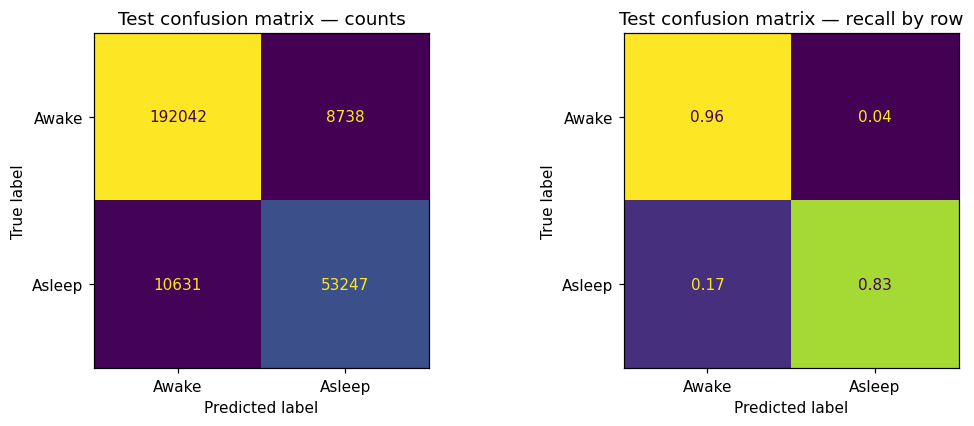

,user_id,seconds,accuracy,awake_recall,asleep_recall
0,1,67936,0.907501,0.993189,0.672758
1,4,64796,0.910874,0.908202,0.921165
2,20,64740,0.943188,0.954610,0.913806
3,21,67186,0.945941,0.970522,0.854483


In [20]:
X_test = test[FEATURE_COLUMNS].replace([np.inf, -np.inf], np.nan).copy()
y_test = test['label'].astype(int).to_numpy()
X_test_scaled = scaler.transform(imputer.transform(X_test)).astype(np.float32)
assert np.isfinite(X_test_scaled).all()
with threadpool_limits(limits=1):
    test_probabilities = model_a.predict_proba(X_test_scaled)[:, 1]
test_predictions = (test_probabilities >= 0.5).astype(int)
majority_label = int(np.bincount(y_train).argmax())
baseline_predictions = np.full_like(y_test, majority_label)
cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
recalls = cm.diagonal() / cm.sum(axis=1)
test_metrics = {'model': selected_run['config']['name'],
    'test_accuracy': float(accuracy_score(y_test, test_predictions)),
    'awake_recall': float(recalls[0]), 'asleep_recall': float(recalls[1]),
    'balanced_accuracy': float(balanced_accuracy_score(y_test, test_predictions)),
    'macro_f1': float(f1_score(y_test, test_predictions, average='macro')),
    'test_log_loss': float(log_loss(y_test, test_probabilities, labels=[0, 1])),
    'majority_baseline_accuracy': float(accuracy_score(y_test, baseline_predictions))}
display(pd.DataFrame([test_metrics]).T.rename(columns={0: 'value'}))
print(classification_report(y_test, test_predictions, labels=[0, 1],
    target_names=['Awake', 'Asleep'], zero_division=0, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(cm, display_labels=['Awake', 'Asleep']).plot(
    ax=axes[0], colorbar=False, values_format='d')
normalised_cm = cm / cm.sum(axis=1, keepdims=True)
ConfusionMatrixDisplay(normalised_cm, display_labels=['Awake', 'Asleep']).plot(
    ax=axes[1], colorbar=False, values_format='.2f')
axes[0].set_title('Test confusion matrix — counts')
axes[1].set_title('Test confusion matrix — recall by row')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'test_confusion_matrices.png', dpi=180)
plt.show()

predictions = test[['user_id', 'timestamp', 'label']].copy()
predictions['predicted_label'] = test_predictions
predictions['probability_asleep'] = test_probabilities
predictions.to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)
per_person = []
for person, rows in predictions.groupby('user_id'):
    person_cm = confusion_matrix(rows['label'], rows['predicted_label'], labels=[0, 1])
    denominators = person_cm.sum(axis=1)
    person_recall = np.divide(person_cm.diagonal(), denominators,
        out=np.full(2, np.nan), where=denominators != 0)
    per_person.append({'user_id': int(person), 'seconds': len(rows),
        'accuracy': accuracy_score(rows['label'], rows['predicted_label']),
        'awake_recall': person_recall[0], 'asleep_recall': person_recall[1]})
per_person_results = pd.DataFrame(per_person)
display(per_person_results)
per_person_results.to_csv(OUTPUT_DIR / 'test_per_person.csv', index=False)
pd.DataFrame(cm, index=['true_awake', 'true_asleep'],
    columns=['predicted_awake', 'predicted_asleep']).to_csv(OUTPUT_DIR / 'confusion_matrix.csv')
(OUTPUT_DIR / 'test_metrics.json').write_text(json.dumps(test_metrics, indent=2))
bundle = {'model': model_a, 'imputer': imputer, 'scaler': scaler,
    'features': FEATURE_COLUMNS, 'label_mapping': {0: 'awake', 1: 'asleep'},
    'selected_config': selected_run['config'], 'selected_epoch': selected_run['best_epoch'],
    'sklearn_version': sklearn.__version__, 'training_seed': SEED}
joblib.dump(bundle, OUTPUT_DIR / 'model_a.joblib')
print('Results written to:', OUTPUT_DIR.resolve())

## Test set: reference rules and per-person timelines
The same fixed rules are applied to the test participants for context. Nothing here is used to change
Model A. The timelines show, for each test person, the labelled sleep period, Model A's probability of
sleep and its 0.5-threshold decision, so errors can be located in time (e.g. sleep onset/offset or
inside the sleep period). Gaps in the recording appear as straight connecting segments.


In [ ]:
test_comparison = pd.DataFrame(
    [summarise('Majority (always awake)', y_test, baseline_predictions)]
    + [summarise(name, y_test, pred) for name, pred in rule_predictions(test).items()]
    + [summarise(f"Model A ({selected_run['config']['name']})", y_test, test_predictions)])
display(test_comparison.round(4))
test_comparison.to_csv(OUTPUT_DIR / 'test_reference_comparison.csv', index=False)

test_people_sorted = sorted(predictions['user_id'].unique())
fig, axes = plt.subplots(len(test_people_sorted), 1, figsize=(12, 2.4 * len(test_people_sorted)), sharex=False)
for axis, person in zip(np.atleast_1d(axes), test_people_sorted):
    rows = predictions[predictions['user_id'] == person].sort_values('timestamp')
    axis.fill_between(rows['timestamp'], 0, rows['label'], step='post', color='tab:grey',
                      alpha=0.3, label='Labelled asleep')
    axis.plot(rows['timestamp'], rows['probability_asleep'], linewidth=0.4, color='tab:blue',
              label='P(asleep)')
    wrong = rows['label'] != rows['predicted_label']
    axis.scatter(rows.loc[wrong, 'timestamp'], np.full(wrong.sum(), 1.05), s=1, color='tab:red',
                 label='Misclassified second')
    axis.set_ylim(-0.05, 1.12)
    axis.set_ylabel(f'Person {person}')
axes[0].legend(loc='upper left', ncol=3, fontsize=8)
axes[-1].set_xlabel('Time (placeholder dates)')
fig.suptitle('Model A on test participants: labels, predicted probability and errors')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'test_timelines.png', dpi=180)
plt.show()


# Model A — discussion (Person 2 to write)

Write this from the outputs above, in your own words:
- **c:** model choice and why it is a different type from Model B.
- **e:** training set-up, tuning table, learning curves and what they show.
- **f:** test accuracy, per-class recall, confusion matrix, comparison with the reference rules,
  per-person variation and timelines, generalisation to unseen people, limitations.
- **Comparison with Model B** on the same features, labels and test participants (with Person 3).
- **AI use**, as actually used.
